# CYP-Relevant Fragment Exploration

## Objective
Explore the distribution and relationships of CYP-relevant chemical
groups in the OpenADMET molecular dataset.

This analysis aims to:
- Determine the prevalence of each CYP-relevant group.
- Identify relationships and overlap between chemical groups.
- Understand which groups may be useful candidates for further
  predictive feature evaluation.

Note: This notebook does not measure predictive usefulness directly.
That will require CYP inhibition labels and model evaluation.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the extracted features
df = pd.read_csv("../data/cyp_features.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (39505, 13)


,smiles,imidazole,"1,2,4-triazole",pyridine,methylenedioxyphenyl,furan / thiophene,steroid core,basic aliphatic amine,carboxylic acid,sulfonamide,phenol,aryl halide,nitro
0,CCCC(=O)Nc1ccc(N2CCN(CC)CC2)c(Cl)c1,0,0,0,0,0,0,1,0,0,0,1,0
1,O=c1[nH]c2cc3c(cc2cc1CN(CCCO)Cc1nnnn1Cc1ccc(F)...,0,0,1,1,0,0,1,0,0,0,1,0
2,CCN1C(=O)/C(=C2\SC(=S)N(CCCOC)C2=O)c2ccccc21,0,0,0,0,0,0,0,0,0,0,0,0
3,CC(=O)N(c1ccc2oc(=O)sc2c1)S(=O)(=O)c1cccs1,0,0,0,0,1,0,0,0,1,0,0,0
4,Clc1ccccc1-c1nc(-c2ccccc2)n[nH]1,0,1,0,0,0,0,0,0,0,0,1,0


In [3]:
# Get CYP feature columns
feature_cols = df.columns.drop("smiles")

# Count molecules containing each group
fragment_counts = df[feature_cols].sum()

# Calculate percentage of molecules
fragment_prevalence = (
    df[feature_cols].mean() * 100
)

# Combine results
prevalence_df = pd.DataFrame({
    "Count": fragment_counts,
    "Prevalence (%)": fragment_prevalence
})

prevalence_df = prevalence_df.sort_values(
    "Prevalence (%)",
    ascending=False
)

display(prevalence_df.round(2))

,Count,Prevalence (%)
aryl halide,12166,30.80
pyridine,11244,28.46
basic aliphatic amine,9263,23.45
imidazole,4659,11.79
sulfonamide,3712,9.40
furan / thiophene,3567,9.03
carboxylic acid,3339,8.45
phenol,2153,5.45
"1,2,4-triazole",1700,4.30
nitro,1088,2.75


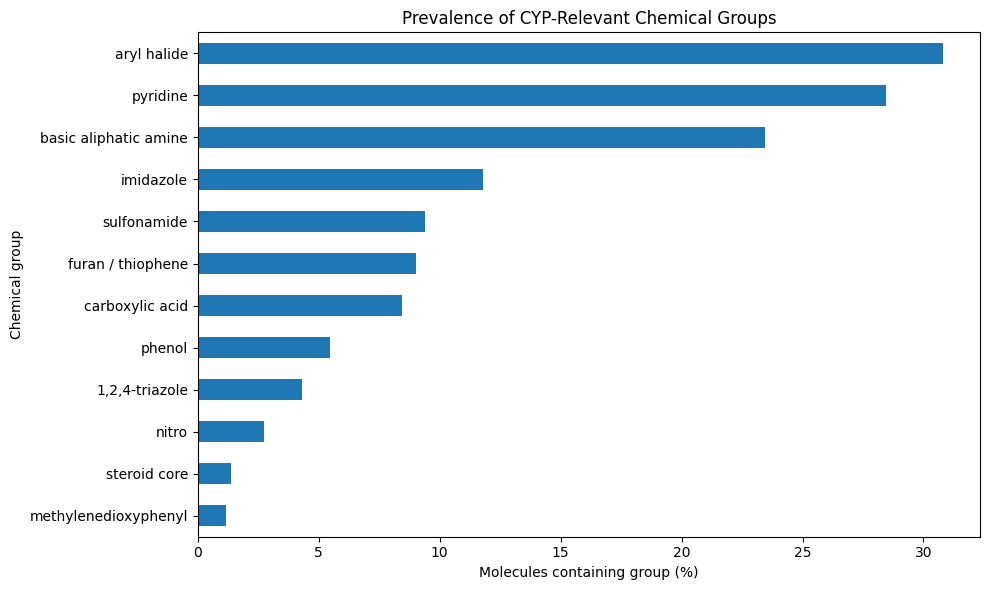

In [4]:
plt.figure(figsize=(10, 6))

prevalence_df["Prevalence (%)"].sort_values().plot(
    kind="barh"
)

plt.title("Prevalence of CYP-Relevant Chemical Groups")
plt.xlabel("Molecules containing group (%)")
plt.ylabel("Chemical group")

plt.tight_layout()
plt.show()

In [5]:
# Count how often each pair of fragments occurs together
co_occurrence = (
    df[feature_cols].T @ df[feature_cols]
)

display(co_occurrence)

,imidazole,"1,2,4-triazole",pyridine,methylenedioxyphenyl,furan / thiophene,steroid core,basic aliphatic amine,carboxylic acid,sulfonamide,phenol,aryl halide,nitro
imidazole,4659,67,1332,27,273,38,740,303,237,146,1509,154
"1,2,4-triazole",67,1700,473,25,189,4,240,17,110,86,660,49
pyridine,1332,473,11244,59,755,44,2176,1179,1016,501,3745,165
methylenedioxyphenyl,27,25,59,461,41,1,88,23,15,18,74,10
furan / thiophene,273,189,755,41,3567,1,693,174,257,77,852,85
steroid core,38,4,44,1,1,544,45,20,0,23,9,6
basic aliphatic amine,740,240,2176,88,693,45,9263,599,572,479,3025,171
carboxylic acid,303,17,1179,23,174,20,599,3339,295,203,896,47
sulfonamide,237,110,1016,15,257,0,572,295,3712,89,1529,153
phenol,146,86,501,18,77,23,479,203,89,2153,415,47


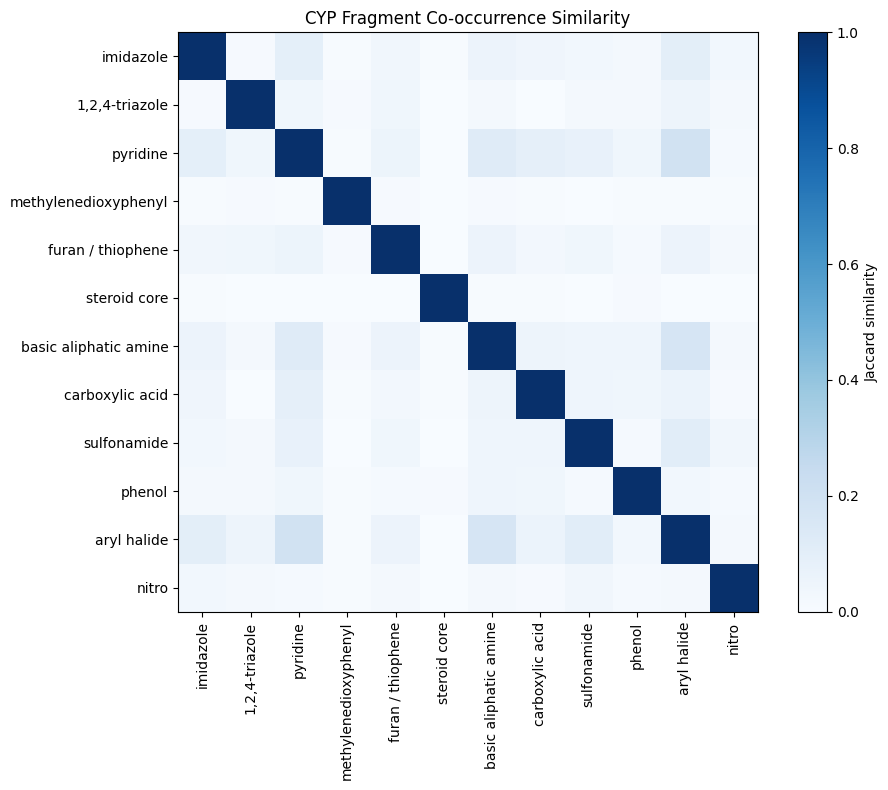

In [6]:
# Calculate Jaccard similarity between fragments
jaccard = pd.DataFrame(
    index=feature_cols,
    columns=feature_cols,
    dtype=float
)

for a in feature_cols:
    for b in feature_cols:
        intersection = ((df[a] == 1) & (df[b] == 1)).sum()
        union = ((df[a] == 1) | (df[b] == 1)).sum()

        jaccard.loc[a, b] = (
            intersection / union if union > 0 else 0
        )

plt.figure(figsize=(10, 8))
plt.imshow(jaccard, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Jaccard similarity")

plt.xticks(
    range(len(feature_cols)),
    feature_cols,
    rotation=90
)
plt.yticks(range(len(feature_cols)), feature_cols)

plt.title("CYP Fragment Co-occurrence Similarity")
plt.tight_layout()
plt.show()

## Initial Findings

### Fragment Prevalence

The most prevalent CYP-relevant chemical groups were aryl halide (30.80%), pyridine (28.46%), and basic aliphatic amine (23.45%). These groups are well represented across the dataset and may be suitable candidates for further predictive feature evaluation.

Other groups, such as imidazole (11.79%) and 1,2,4-triazole (4.30%), were less common but still occurred in a substantial number of molecules. The least prevalent groups were steroid core (1.38%) and methylenedioxyphenyl (1.17%), which may be more difficult to evaluate reliably in smaller labeled subsets.

### Fragment Co-occurrence

The Jaccard similarity heatmap indicates relatively low overlap between most CYP-relevant chemical groups. Some overlap was observed between pyridine and aryl halide, as well as basic aliphatic amine and aryl halide, but no pair showed particularly strong similarity.

These results suggest that the selected fragments describe different aspects of molecular structure, although their predictive independence has not yet been established.

### Next Steps

The next step is to compare fragment distributions across the scored and blind datasets and determine whether the chemical composition differs between them.

Afterward, fragment indicators can be matched with CYP inhibition measurements to evaluate their predictive usefulness, both individually and alongside other molecular features.